# 实验报告：树莓派控制小车运动
卢冉 20307130309\
彭星语 24301010047

## 实验目的：
* 掌握树莓派的基本操作和环境配置。
*  学习RO）的安装与配置
* 实现通过键盘控制小车的基本操作

## 实验配置：
* 硬件配置：
  1. 电脑、树莓派、TF卡以及读卡器
  2. 小车底盘、轮子、电机驱动器、电池、杜邦线等。
* 软件配置： Ubuntu操作系统、ROS

## 实验步骤：

### 树莓派操作系统烧录
1. 下载树莓派镜像烧录器准备使用
2. 通过读卡器在电脑上操作TF卡
3. 根据助教的指示步骤，分别确定树莓派版本、操作系统版本与存储卡
4. **出现的问题**：
操作系统版本选择错误，忽略了server，以至于后期没有弹出编辑设置的选项
5. **解决方法**：经队友提示后重新核对步骤，发现了问题。在演示文档中，TF卡内存是62.9GB，但是当重新烧录时，发现选择存储卡时显示31.2GB，一度担心会不会是之前的下载占用内存，后续提示烧录时会删除TF卡所有已有内容，遂放下心来重新烧录。

### 安装ROS操作系统
**1. 确定树莓派ip地址**
* 出现的问题：树莓派迟迟未连接上手机Wi-Fi
* 解决方法：先后确定是否是手机、树莓派、TF卡、烧录过程出现了问题。以上步骤确定无误后，最后通过不断重启与等待解决。
  
**2. 电脑连接到树莓派终端**
* 电脑终端的连接进展顺利，没有出现问题。
  
**3. 用VS Code远程连接树莓派**\
**问题：** 这一步出现了最难以解决的问题，也是软件配置中耗时最多的部分。无论如何在VS Code中输入用户名和地址，最终都显示无法连接。\
**解决过程：**
* 首先，我们根据error的提示，发现超时连接失败的原因时上面提示框中树莓派的密码没有输入。当我们输入密码后，仍然显示失败。出现了如下提示：
>(base) <user>@<hostname> ~ % sudo raspi-config\
Password:\
sudo: raspi-config: command not found
* 根据提示，我们先在电脑终端远程连接树莓派的窗口里，执行下载config的命令。当时我们不确定是在本机上下载config还是在树莓派上下载，所以先尝试了树莓派(最后证明确实是树莓派）。
>bash \
ssh <user>@<raspberry-pi-ip> \
sudo apt update \
sudo apt install raspi-config
* 依然没有成功，提示错误如下，有点看不懂，依靠人工智能解释尝试理解,认为问题应该是VS Code的Remote - SSH 扩展。 
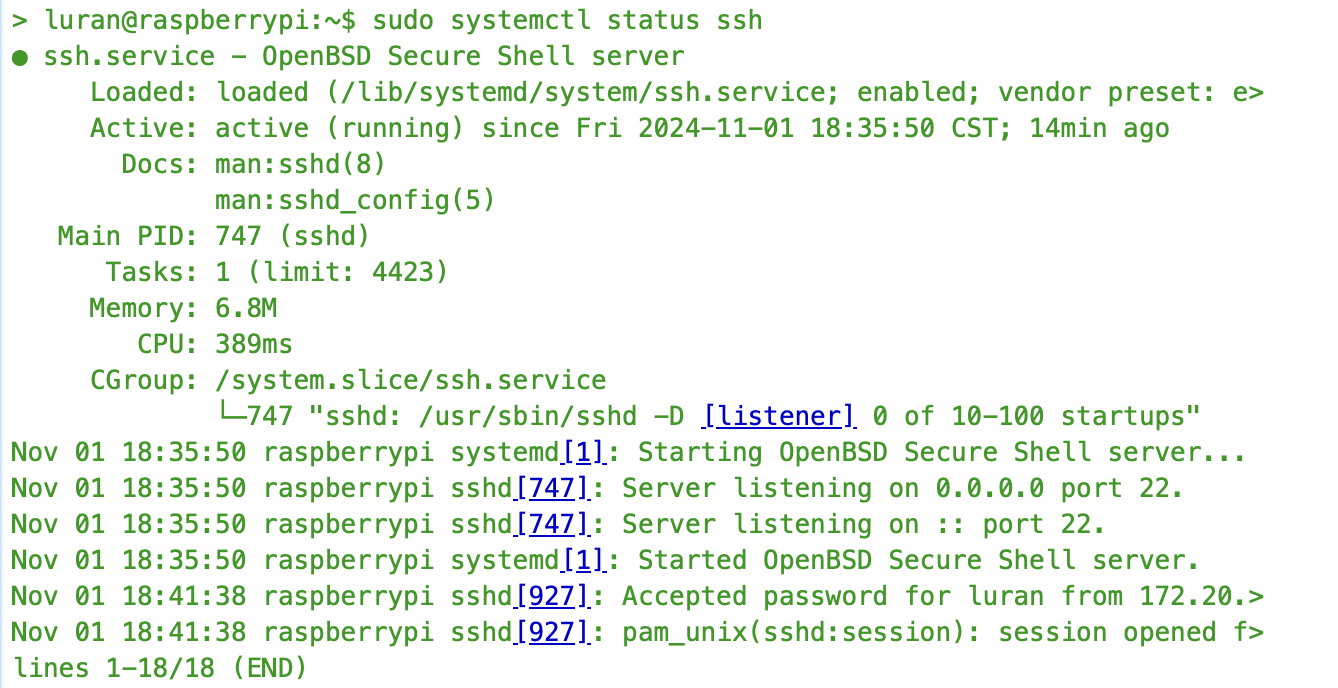
* 解决：依靠人工智能，在终端创建 SSH 配置文件：
> bash\
> nano ~/.ssh/config

    并添加以下内容，确保 IP 地址和用户名正确：(在终端操作文件编写有点不熟悉，查网上的文档解决了）
>    Host raspberrypi\
        HostName <raspberry-pi-ip>\
        User <user>\
        Port 22

    重启 SSH 服务，然后重新打开 VS Code 进行连接：
>bash\
>sudo systemctl restart ssh

    在 VS Code 中重新启动 SSH 服务器： 
>   1. 打开 Remote - SSH 菜单：在 VS Code 界面，按下 Ctrl + Shift + P（或 Cmd + Shift + P），输入 Remote-SSH: Connect to Host... 并选择该选项。
>   2. 选择 Host 进行连接：选择了命名为raspberrypi的文件。点击它，VS Code 会开始连接。
>   3. 输入树莓派的密码，确保连接成功。
>   4. 等待 VS Code 初始化：第一次连接时，VS Code 在树莓派上自动安装 VS Code Server，等待了几分钟。完成后，在 VS Code 界面左下角看到 “SSH: raspberrypi”。

5. 安装ROS操作系统
* 按照指示安装，并没有出现太大问题，但是安装过程很缓慢，总计持续了1h左右。
6. Ubuntu系统确定ROS的位置
* 在树莓派终端执行此操作，并且出现问题。

### 控制代码的运行
* 在树莓派的终端输入指令，成功创建project和功能包。此步没有出现太大问题，但是没能详细学习功能包的含义，我们将它理解为ros系统自带的库。
* 创建工作区
>mkdir -p  ~/HAPPYPROJECT/src \
cd HAPPYPROJECT/src
* 创建功能包
>ros2 pkg create wheels --build-type ament_python --dependencies rclpy
* 在终端下载包：
> sudo apt install python3-gpiozero python3-pigpio
* 修改并整理motor_control.py和setup.py
* 激活环境与motor_control.py代码：
> source install/setup.bash  
ros2 run wheels motor_control  
* 运行键盘控制节点：
> ros2 run teleop_twist_keyboard teleop_twist_keyboard

## 实验总结
* 实验结果：按照键盘的命令指示，使用键盘控制小车运动，并拍摄成果视频。但是发现问题：
1. 小车运行轨迹不准确，经常发生转圈情况
2. 在运行中，树莓派突然断联Wi-Fi

* 为此，我们作出改进：
1. 重新加固拧紧小车
2. 换到摩擦力更大的地面
3. 将树莓派再次连接电源，发现一开始就不闪黄灯，猜测电源不足导致TF卡无法正常工作。尝试给电源充电后仍然出现此问题，遂借同学的电源重新连接使用。

* 不足与后续学习之处：
1. 直接使用了老师的代码，对代码理解不够深刻，在后一步实验中希望加强训练。